In [1]:
# Upgrade pip and install ML/data libraries
!pip install --upgrade pip
!pip install datasets scikit-learn tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.7 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


##Import Libraries & Define Hyperparameters

In [2]:
import os
import numpy as np
import tensorflow as tf
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import classification_report, confusion_matrix

# — Hyperparameters —
MAX_VOCAB   = 20_000    # number of words the tokenizer keeps
MAX_LEN     = 100       # max tokens per statement
EMBED_DIM   = 100       # dimension of GloVe embeddings
GRU_UNITS   = 64        # cells in the GRU layer
BATCH_SIZE  = 128
EPOCHS      = 10
DROPOUT     = 0.2
RECURRENT_DROPOUT = 0.2


### Fetch & Unzip the Dataset

In [3]:
!wget https://www.cs.ucsb.edu/~william/data/liar_dataset.zip \
     -O /content/liar_dataset.zip

!unzip -q /content/liar_dataset.zip -d /content/liar_data

!ls /content/liar_data

--2025-06-10 18:18:06--  https://www.cs.ucsb.edu/~william/data/liar_dataset.zip
Resolving www.cs.ucsb.edu (www.cs.ucsb.edu)... 23.185.0.253, 2620:12a:8001::253, 2620:12a:8000::253
Connecting to www.cs.ucsb.edu (www.cs.ucsb.edu)|23.185.0.253|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://sites.cs.ucsb.edu/~william/data/liar_dataset.zip [following]
--2025-06-10 18:18:06--  https://sites.cs.ucsb.edu/~william/data/liar_dataset.zip
Resolving sites.cs.ucsb.edu (sites.cs.ucsb.edu)... 128.111.27.164
Connecting to sites.cs.ucsb.edu (sites.cs.ucsb.edu)|128.111.27.164|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1013571 (990K) [application/zip]
Saving to: ‘/content/liar_dataset.zip’

/content/liar_datas 100%[===================>] 989.82K  1.06MB/s    in 0.9s    

2025-06-10 18:18:08 (1.06 MB/s) - ‘/content/liar_dataset.zip’ saved [1013571/1013571]

README	test.tsv  train.tsv  valid.tsv


### Load the TSVs with pandas

In [4]:
import os
import pandas as pd
import csv

DATA_DIR = "/content/liar_data"

# Column names
COLS = [
    "id","label","statement","subject","speaker","job_title","state_info",
    "party_affiliation","barely_true_counts","false_counts",
    "half_true_counts","mostly_true_counts","pants_on_fire_counts","context"
]

# Read each split
train_df = pd.read_csv(
    os.path.join(DATA_DIR, "train.tsv"),
    sep='\t',
    header=None,
    names=COLS,
    quoting=csv.QUOTE_NONE
)
val_df = pd.read_csv(
    os.path.join(DATA_DIR, "valid.tsv"),
    sep='\t',
    header=None,
    names=COLS,
    quoting=csv.QUOTE_NONE
)
test_df = pd.read_csv(
    os.path.join(DATA_DIR, "test.tsv"),
    sep='\t',
    header=None,
    names=COLS,
    quoting=csv.QUOTE_NONE
)


print("Train shape:", train_df.shape)
print("Val   shape:", val_df.shape)
print("Test  shape:", test_df.shape)

Train shape: (10269, 14)
Val   shape: (1284, 14)
Test  shape: (1283, 14)


### Inspect Label Distribution

In [5]:
print("Raw label counts (train):")
print(train_df["label"].value_counts(), "\n")

pct = (train_df["label"].value_counts(normalize=True) * 100).round(2)
print("Percent distribution (train):")
print(pct)

Raw label counts (train):
label
half-true      2123
false          1998
mostly-true    1966
true           1683
barely-true    1657
pants-fire      842
Name: count, dtype: int64 

Percent distribution (train):
label
half-true      20.67
false          19.46
mostly-true    19.14
true           16.39
barely-true    16.14
pants-fire      8.20
Name: proportion, dtype: float64


### Map Text Labels → Numeric Classes

In [6]:
label_list = [
    "false",       # 0
    "half-true",   # 1
    "mostly-true", # 2
    "true",        # 3
    "barely-true", # 4
    "pants-fire"   # 5
]

In [7]:
label_map = {lab: idx for idx, lab in enumerate(label_list)}

for df in (train_df, val_df, test_df):
    df["label"] = df["label"].map(label_map)

# Verify mapping
print("Numeric label counts (train):")
print(train_df["label"].value_counts().sort_index())

Numeric label counts (train):
label
0    1998
1    2123
2    1966
3    1683
4    1657
5     842
Name: count, dtype: int64


## Tokenization & Padding

In [8]:
MAX_VOCAB = 20_000

# We’ll pad or truncate every statement to 100 tokens.
MAX_LEN   = 100

### Initialize and Fit the Tokenizer

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Create the tokenizer
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")

tokenizer.fit_on_texts(train_df["statement"])

### Convert Texts to Sequences & Pad

In [10]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

def encode_texts(texts):
    # 1) Map words to integers
    seqs = tokenizer.texts_to_sequences(texts)
    # 2) Pad short sequences with zeros; truncate long ones
    return pad_sequences(
        seqs,
        maxlen=MAX_LEN,
        padding='post',
        truncating='post'
    )

# Encode & pad all splits
X_train = encode_texts(train_df["statement"])
X_val   = encode_texts(val_df["statement"])
X_test  = encode_texts(test_df["statement"])

# Extract the numeric labels
y_train = train_df["label"].values
y_val   = val_df["label"].values
y_test  = test_df["label"].values


### Verify Your Preprocessed Data

In [11]:
# Check shapes: should be (num_examples, MAX_LEN)
print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape)
print("X_val   shape:", X_val.shape,   "y_val   shape:", y_val.shape)
print("X_test  shape:", X_test.shape,  "y_test  shape:", y_test.shape)

# Inspect the size of your effective vocabulary
vocab_size = min(MAX_VOCAB, len(tokenizer.word_index)) + 1
print("Effective vocabulary size:", vocab_size)


X_train shape: (10269, 100) y_train shape: (10269,)
X_val   shape: (1284, 100) y_val   shape: (1284,)
X_test  shape: (1283, 100) y_test  shape: (1283,)
Effective vocabulary size: 12349


### Set Paths & Dimensions

In [12]:
# Dimensions
EMBED_DIM = 100

glove_path = "/content/drive/MyDrive/ColabProjects/LIAR_GRU/embeddings/glove.6B.100d.txt"

### Load GloVe into a Python Dict

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
!ls "/content/drive/MyDrive/ColabProjects/LIAR_GRU/embeddings"

embedding_matrix.npy  glove.6B.100d.txt


In [15]:
glove_path = "/content/drive/MyDrive/ColabProjects/LIAR_GRU/embeddings/glove.6B.100d.txt"

In [16]:
emb_index = {}
with open(glove_path, encoding='utf8') as f:
    for line in f:
        word, *vec = line.rstrip().split()
        emb_index[word] = np.array(vec, dtype='float32')
print(f"Loaded {len(emb_index)} vectors.")

Loaded 400001 vectors.


In [17]:
# 2) Decide how many rows we need
vocab_size = min(MAX_VOCAB, len(tokenizer.word_index)) + 1

# 3) Initialize a matrix of zeros
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))

# 4) For each word in our tokenizer’s index, if it exists in GloVe, copy its vector
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size:
        vec = emb_index.get(word)
        if vec is not None:
            embedding_matrix[idx] = vec

print("Embedding matrix shape:", embedding_matrix.shape)


Embedding matrix shape: (12349, 100)


In [18]:
# Quick check: a few random indices should be non-zero
nonzero = np.count_nonzero(embedding_matrix)
print(f"{nonzero} / {vocab_size*EMBED_DIM} total values are non-zero.")

# (Optional) Save the matrix to Drive for faster reloads
np.save("/content/drive/MyDrive/ColabProjects/LIAR_GRU/embeddings/embedding_matrix.npy",
        embedding_matrix)


1159500 / 1234900 total values are non-zero.


### Define Model Architecture

In [20]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

# ─── Hyperparams & vocab_size ───────────────────────────────────────────────
# (make sure MAX_VOCAB, MAX_LEN, EMBED_DIM, tokenizer, embedding_matrix are in scope)
vocab_size = min(MAX_VOCAB, len(tokenizer.word_index)) + 1

# ─── Build the upgraded model with input_shape ──────────────────────────────
model = Sequential([
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMBED_DIM,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        input_shape=(MAX_LEN,),     # ← this line forces the build
        trainable=False
    ),
    layers.Bidirectional(
        layers.GRU(128, dropout=0.1, recurrent_dropout=0.1, return_sequences=False)
    ),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(6, activation='softmax')
])

# ─── (Optional alternative) build manually instead of input_shape ───────────
# model.build(input_shape=(None, MAX_LEN))

# ─── Compile & inspect ───────────────────────────────────────────────────────
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(1e-4),
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 100)       │     1,234,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       176,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428,378 (5.45 MB)

 Trainable params: 193,478 (755.77 KB)

 Non-trainable params: 1,234,900 (4.71 MB)

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 100)       │     1,234,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       176,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428,378 (5.45 MB)

 Trainable params: 193,478 (755.77 KB)

 Non-trainable params: 1,234,900 (4.71 MB)

In [22]:
# ─── New Cell: Compute class weights ─────────────────────────────────────────
from sklearn.utils import class_weight
import numpy as np

# Balanced weights for y_train (0–5 integer labels)
weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(weights))
print("Class weights:", class_weights)


Class weights: {0: np.float64(0.8566066066066066), 1: np.float64(0.8061705134243994), 2: np.float64(0.8705493387589013), 3: np.float64(1.016934046345811), 4: np.float64(1.0328907664453832), 5: np.float64(2.0326603325415675)}


In [23]:
# ─── In your Step 6 training cell, before model.fit() ────────────────────────
# 1) Unfreeze embeddings for fine-tuning
model.layers[0].trainable = True

# 2) Re-compile with a low learning rate
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(1e-5),
    metrics=['accuracy']
)

### Training with Checkpoints

In [25]:
import tensorflow as tf

#  Define your callbacks here at the top of this very cell
ckpt_path = "/content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5"
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=ckpt_path,
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)
earlystop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

# Collect them into a list
callbacks = [checkpoint_cb, earlystop_cb, reduce_lr_cb]

# 2) Now right below, call model.fit using those callbacks
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,        # ← uses the list you defined
    class_weight=class_weights  # if you are still using class weights
)


Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.1831 - loss: 1.8101
Epoch 1: val_accuracy improved from -inf to 0.14564, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 59s 595ms/step - accuracy: 0.1830 - loss: 1.8102 - val_accuracy: 0.1456 - val_loss: 1.8083 - learning_rate: 1.0000e-05
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.1742 - loss: 1.8167
Epoch 2: val_accuracy improved from 0.14564 to 0.16667, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 76s 560ms/step - accuracy: 0.1742 - loss: 1.8166 - val_accuracy: 0.1667 - val_loss: 1.8005 - learning_rate: 1.0000e-05
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 529ms/step - accuracy: 0.1790 - loss: 1.8037
Epoch 3: val_accuracy improved from 0.16667 to 0.17445, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 81s 553ms/step - accuracy: 0.1790 - loss: 1.8038 - val_accuracy: 0.1745 - val_loss: 1.7965 - learning_rate: 1.0000e-05
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.1879 - loss: 1.8049
Epoch 4: val_accuracy improved from 0.17445 to 0.18069, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 46s 570ms/step - accuracy: 0.1879 - loss: 1.8049 - val_accuracy: 0.1807 - val_loss: 1.7941 - learning_rate: 1.0000e-05
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 529ms/step - accuracy: 0.1801 - loss: 1.8101
Epoch 5: val_accuracy improved from 0.18069 to 0.18380, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 80s 550ms/step - accuracy: 0.1800 - loss: 1.8100 - val_accuracy: 0.1838 - val_loss: 1.7926 - learning_rate: 1.0000e-05
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 533ms/step - accuracy: 0.1798 - loss: 1.8026
Epoch 6: val_accuracy did not improve from 0.18380
81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 553ms/step - accuracy: 0.1798 - loss: 1.8026 - val_accuracy: 0.1807 - val_loss: 1.7922 - learning_rate: 1.0000e-05
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.1729 - loss: 1.8096
Epoch 7: val_accuracy did not improve from 0.18380
81/81 ━━━━━━━━━━━━━━━━━━━━ 81s 537ms/step - accuracy: 0.1729 - loss: 1.8095 - val_accuracy: 0.1729 - val_loss: 1.7922 - learning_rate: 1.0000e-05
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 532ms/step - accuracy: 0.1919 - loss: 1.7968
Epoch 8: val_accuracy did not improve from 0.18380
81/81 ━━━━━━━━━━━━━━━━━━━━ 84s 565ms/step - accuracy: 0.1918 - loss: 1.7968 - val_accuracy: 0.1745 - val_loss: 1.7909 - learning_rate: 1.0000e-05
Epoch

In [26]:
model.load_weights(ckpt_path)

## Callback Setup

In [27]:
import tensorflow as tf

# Path to save the best‐performing model weights
ckpt_path = "/content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5"

# Only keep the weights that give the highest validation accuracy
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=ckpt_path,
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

# Stop early if val_accuracy hasn’t improved in 3 epochs
earlystop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate by half if val_loss plateaus for 2 epochs
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

callbacks = [checkpoint_cb, earlystop_cb, reduce_lr_cb]

In [28]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 532ms/step - accuracy: 0.1840 - loss: 1.7899
Epoch 1: val_accuracy improved from -inf to 0.20249, saving model to /content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5


81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 555ms/step - accuracy: 0.1840 - loss: 1.7899 - val_accuracy: 0.2025 - val_loss: 1.7810 - learning_rate: 1.0000e-05
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 535ms/step - accuracy: 0.1948 - loss: 1.7863
Epoch 2: val_accuracy did not improve from 0.20249
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 552ms/step - accuracy: 0.1948 - loss: 1.7863 - val_accuracy: 0.2025 - val_loss: 1.7732 - learning_rate: 1.0000e-05
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 527ms/step - accuracy: 0.1979 - loss: 1.7759
Epoch 3: val_accuracy did not improve from 0.20249
81/81 ━━━━━━━━━━━━━━━━━━━━ 81s 544ms/step - accuracy: 0.1979 - loss: 1.7758 - val_accuracy: 0.1994 - val_loss: 1.7679 - learning_rate: 1.0000e-05
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.2042 - loss: 1.7713
Epoch 4: val_accuracy did not improve from 0.20249
81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 541ms/step - accuracy: 0.2042 - loss: 1.7713 - val_accuracy: 0.2017 - val_loss: 1.7642 - learning_rate: 1.0000e-05
Epoch

### Visualize Training Curves

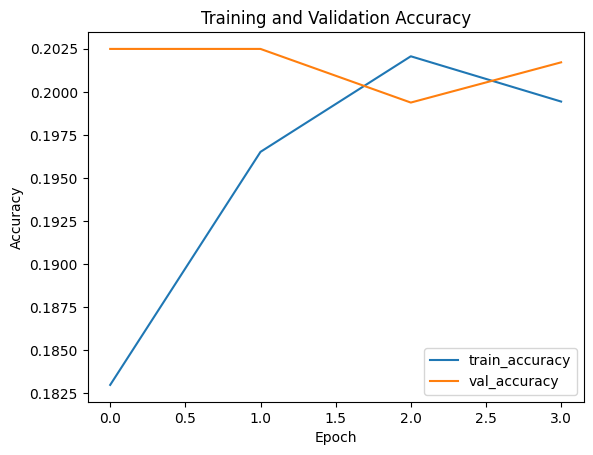

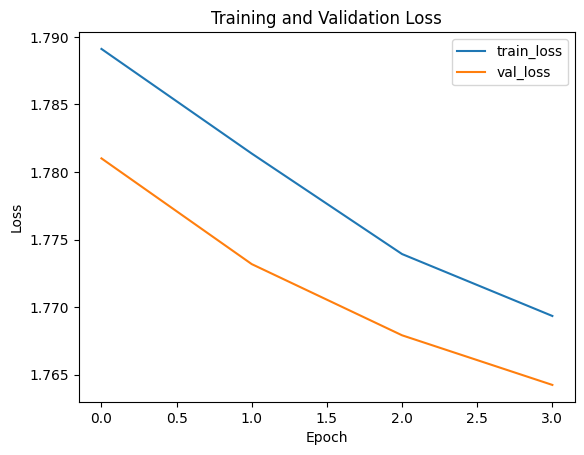

In [51]:
import matplotlib.pyplot as plt

# 1) Accuracy plot
plt.figure()
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

# 2) Loss plot
plt.figure()
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [52]:
# Reload the best‐performing weights
model.load_weights("/content/drive/MyDrive/ColabProjects/LIAR_GRU/checkpoints/best_model.h5")

In [53]:
# ─── New Cell after Step 7 evaluation ─────────────────────────────────────────
import numpy as np

# How many times each class was predicted?
print("Pred counts:", np.bincount(y_pred))

# And how that compares to the true distribution:
print("True counts:", np.bincount(y_test))

Pred counts: [453 461 107  56 200   6]
True counts: [250 267 249 211 214  92]


In [54]:
# Get class‐probabilities then the argmax index
y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE)
y_pred       = y_pred_probs.argmax(axis=1)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step


In [55]:
test_acc = (y_pred == y_test).mean()
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Accuracy: 20.97%


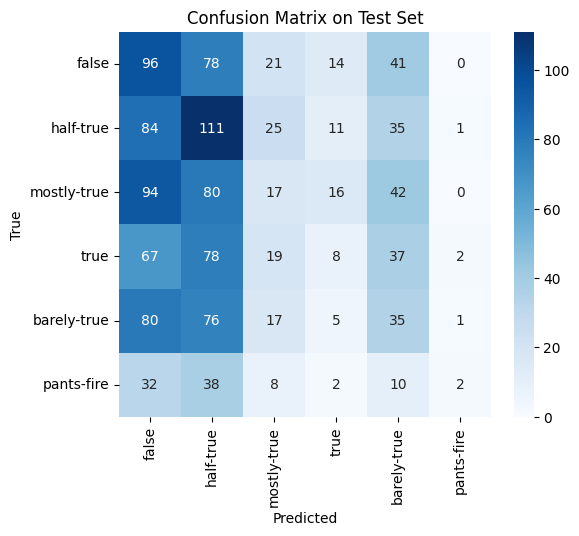

In [56]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_list, yticklabels=label_list)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix on Test Set")
plt.show()

In [57]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_list,
    digits=4
))

              precision    recall  f1-score   support

       false     0.2119    0.3840    0.2731       250
   half-true     0.2408    0.4157    0.3049       267
 mostly-true     0.1589    0.0683    0.0955       249
        true     0.1429    0.0379    0.0599       211
 barely-true     0.1750    0.1636    0.1691       214
  pants-fire     0.3333    0.0217    0.0408        92

    accuracy                         0.2097      1283
   macro avg     0.2105    0.1819    0.1572      1283
weighted avg     0.1988    0.2097    0.1762      1283



In [58]:
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from tensorflow.keras.metrics import sparse_top_k_categorical_accuracy

# 1) Loss & Accuracy
test_loss, test_acc = model.evaluate(X_test, y_test,
                                     batch_size=BATCH_SIZE,
                                     verbose=0)
print(f"Test Loss:       {test_loss:.4f}")
print(f"Test Accuracy:   {test_acc*100:.2f}%")

# 2) Top‐3 Accuracy
y_pred_probs = model.predict(X_test, batch_size=BATCH_SIZE)
top3_array   = sparse_top_k_categorical_accuracy(y_test, y_pred_probs, k=3)
test_top3    = np.mean(top3_array)
print(f"Test Top‐3 Acc:  {test_top3*100:.2f}%")

# 3) Precision/Recall/F1 (weighted)
from sklearn.metrics import classification_report
report = classification_report(
    y_test,
    y_pred_probs.argmax(axis=1),
    target_names=label_list,
    output_dict=True
)
wp = report['weighted avg']['precision']
wr = report['weighted avg']['recall']
wf = report['weighted avg']['f1-score']
print(f"Test Precision (weighted): {wp:.4f}")
print(f"Test Recall    (weighted): {wr:.4f}")
print(f"Test F1 Score  (weighted): {wf:.4f}")

# 4) AUC (OVR, weighted)
y_test_bin = label_binarize(y_test, classes=range(len(label_list)))
test_auc   = roc_auc_score(y_test_bin, y_pred_probs,
                          average='weighted', multi_class='ovr')
print(f"Test AUC (OVR, weighted):  {test_auc:.4f}")


Test Loss:       1.7778
Test Accuracy:   20.97%
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step
Test Top‐3 Acc:  58.07%
Test Precision (weighted): 0.1988
Test Recall    (weighted): 0.2097
Test F1 Score  (weighted): 0.1762
Test AUC (OVR, weighted):  0.5186
